# AI-Powered Precision Irrigation and Crop Water Intelligence System

Single notebook combining all three experimental stages of the project. Run the cells from top to bottom.

**Dataset:** `dataset_zone_1.csv` (33,259 records, 18 columns, 10-minute interval). Place it in `/content/` (Colab) or upload it when prompted.

| Stage | Content |
|---|---|
| 1 | Baseline models, feature-selection comparison, two-stage irrigation prediction |
| 2 | Six models, F-test feature selection, randomized tuning, stacking ensemble |
| 3 | Grid search (135 combinations) and prediction time |


---

# Stage 1: Baseline models, feature-selection comparison and two-stage irrigation prediction

Four regression models (RF, XGBoost, SVR, Stacking), feature selection (SelectKBest-MI, RFE, PCA) and the two-stage event + duration predictor. Uses 12 features (columns with >50% missing values removed).


In [ ]:
!pip install xgboost

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import Lasso

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.svm import SVR
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv("dataset_zone_1.csv")

print("Dataset Shape:", df.shape)

print("\nFirst Five Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

NameError: name 'pd' is not defined

In [ ]:
import pandas as pd

df = pd.read_csv("/content/dataset_zone_1.csv")

# Convert timestamp into useful features
df["ts"] = pd.to_datetime(df["ts"])
df["hour"] = df["ts"].dt.hour
df["day"] = df["ts"].dt.day
df["month"] = df["ts"].dt.month

# Remove timestamp and sensor columns with over 50% missing values
df = df.drop(columns=["ts"])
missing_percent = df.isnull().mean()
remove_cols = missing_percent[missing_percent > 0.50].index.tolist()
df = df.drop(columns=remove_cols)

# Fill remaining missing values using median
df = df.fillna(df.median())

# Separate features and target
X = df.drop(columns=["irrigation_duration_minutes", "liters_total"])
y = df["irrigation_duration_minutes"]

print("Removed columns:", remove_cols)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Remaining missing values:", df.isnull().sum().sum())
print("Rows with irrigation:", (y > 0).sum())
print("Dataset preparation completed!")

Removed columns: ['outside_temperature', 'inside_temperature', 'outside_humidity', 'inside_humidity', 'ec', 'soil_moisture']
Feature shape: (33259, 12)
Target shape: (33259,)
Remaining missing values: 0
Rows with irrigation: 718
Dataset preparation completed!


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import pandas as pd
import numpy as np

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Define models
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBRegressor(
        n_estimators=100, max_depth=4, learning_rate=0.1,
        random_state=42, n_jobs=-1
    ),
    "SVR": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf")
    ),
    "Stacking Ensemble": StackingRegressor(
        estimators=[
            ("rf", RandomForestRegressor(
                n_estimators=100, random_state=42, n_jobs=-1
            )),
            ("xgb", XGBRegressor(
                n_estimators=100, max_depth=4,
                learning_rate=0.1, random_state=42, n_jobs=-1
            )),
            ("svr", make_pipeline(StandardScaler(), SVR()))
        ],
        final_estimator=Ridge(),
        cv=3,
        n_jobs=-1
    )
}

# Train and evaluate
results = []

for name, model in models.items():
    print("Training:", name)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
print("\nMODEL COMPARISON RESULTS")
display(results_df)

Training: Random Forest
Training: XGBoost
Training: SVR
Training: Stacking Ensemble

MODEL COMPARISON RESULTS


,Model,MAE,RMSE,R2 Score
3,Stacking Ensemble,0.137928,0.573956,0.821234
0,Random Forest,0.118903,0.602784,0.802825
1,XGBoost,0.313763,1.072284,0.376052
2,SVR,0.236984,1.351388,0.008966


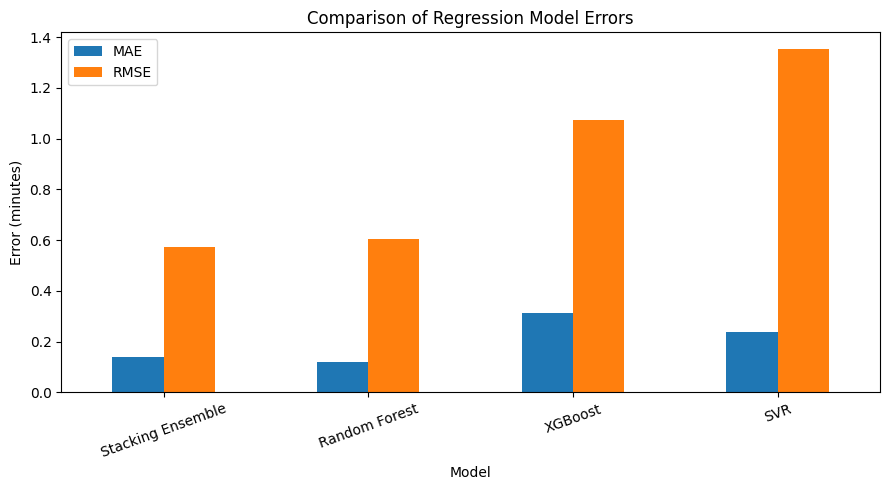

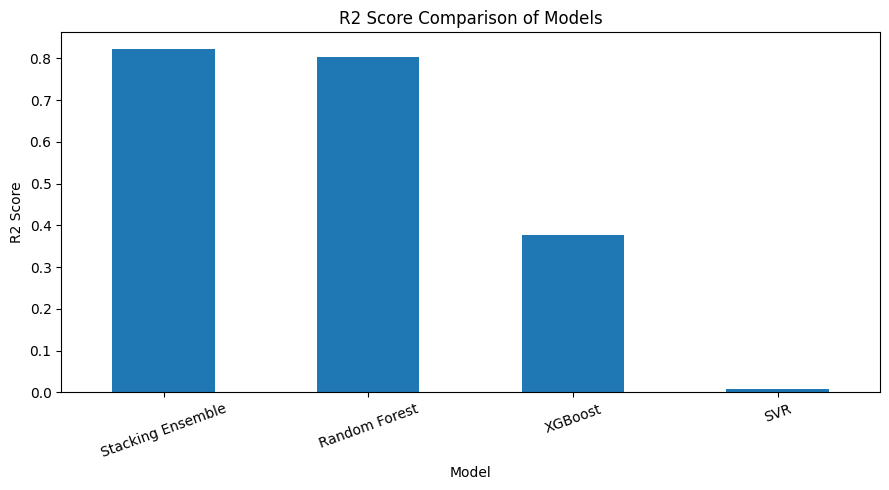

In [ ]:
import matplotlib.pyplot as plt

# Compare MAE and RMSE
results_df.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Comparison of Regression Model Errors")
plt.ylabel("Error (minutes)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("model_error_comparison.png", dpi=300)
plt.show()

# Compare R2 scores
results_df.set_index("Model")["R2 Score"].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("R2 Score Comparison of Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("model_r2_comparison.png", dpi=300)
plt.show()

In [ ]:
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,
    r2_score, precision_score, recall_score, f1_score
)
import numpy as np
import pandas as pd

# Predict using the trained Stacking Ensemble
model = models["Stacking Ensemble"]
pred = model.predict(X_test)

# Evaluate rows where irrigation actually occurred
mask = y_test > 0

print("Actual irrigation rows in test set:", mask.sum())

if mask.sum() > 0:
    print("MAE on irrigation rows:",
          mean_absolute_error(y_test[mask], pred[mask]))
    print("RMSE on irrigation rows:",
          np.sqrt(mean_squared_error(y_test[mask], pred[mask])))
    print("R2 on irrigation rows:",
          r2_score(y_test[mask], pred[mask]))

# Check whether the model detects irrigation events
threshold = 0.5
actual_events = (y_test > 0).astype(int)
predicted_events = (pred > threshold).astype(int)

print("\nIrrigation Event Detection")
print("Precision:", precision_score(
    actual_events, predicted_events, zero_division=0))
print("Recall:", recall_score(
    actual_events, predicted_events, zero_division=0))
print("F1 Score:", f1_score(
    actual_events, predicted_events, zero_division=0))

Actual irrigation rows in test set: 141
MAE on irrigation rows: 2.4099654521777993
RMSE on irrigation rows: 3.2365512607003977
R2 on irrigation rows: -1.5446436406650963

Irrigation Event Detection
Precision: 0.39204545454545453
Recall: 0.9787234042553191
F1 Score: 0.5598377281947262


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Convert duration into an irrigation / no-irrigation label
y_train_event = (y_train > 0).astype(int)
y_test_event = (y_test > 0).astype(int)

# Train a classifier
classifier = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

classifier.fit(X_train, y_train_event)

# Predict irrigation events
event_pred = classifier.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test_event, event_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_event, event_pred,
    target_names=["No Irrigation", "Irrigation"],
    zero_division=0
))

Confusion Matrix:
[[6507    4]
 [  25  116]]

Classification Report:
               precision    recall  f1-score   support

No Irrigation       1.00      1.00      1.00      6511
   Irrigation       0.97      0.82      0.89       141

     accuracy                           1.00      6652
    macro avg       0.98      0.91      0.94      6652
 weighted avg       1.00      1.00      1.00      6652



In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Select rows with actual irrigation in training data
train_mask = y_train > 0

X_train_irrigation = X_train.loc[train_mask]
y_train_irrigation = y_train.loc[train_mask]

# Train duration prediction model
duration_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

duration_model.fit(X_train_irrigation, y_train_irrigation)

# Evaluate only actual irrigation events in test data
test_mask = y_test > 0

X_test_irrigation = X_test.loc[test_mask]
y_test_irrigation = y_test.loc[test_mask]

duration_pred = duration_model.predict(X_test_irrigation)

print("Duration Prediction Results")
print("MAE:", mean_absolute_error(y_test_irrigation, duration_pred))
print("RMSE:", np.sqrt(mean_squared_error(
    y_test_irrigation, duration_pred
)))
print("R2 Score:", r2_score(y_test_irrigation, duration_pred))

Duration Prediction Results
MAE: 1.0386879432624112
RMSE: 2.00590268143195
R2 Score: 0.022578901725275657


Baseline MAE: 1.4258883685484964
Random Forest MAE: 1.0386879432624112


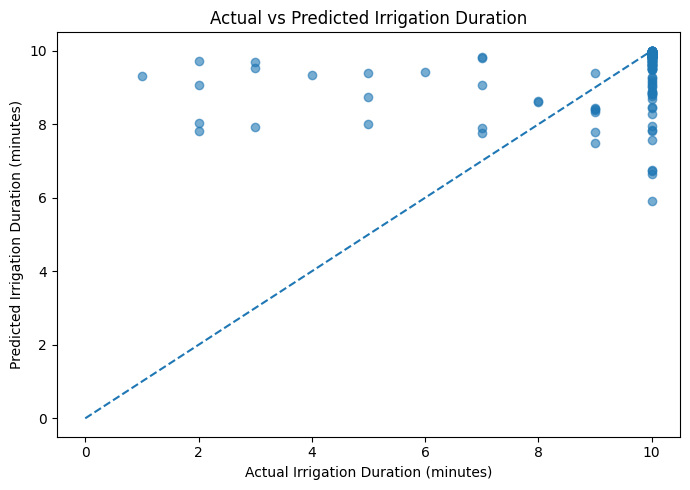

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error

# Baseline: predict the average training irrigation duration
baseline_value = y_train[y_train > 0].mean()
baseline_pred = np.full(len(y_test_irrigation), baseline_value)

print("Baseline MAE:",
      mean_absolute_error(y_test_irrigation, baseline_pred))
print("Random Forest MAE:",
      mean_absolute_error(y_test_irrigation, duration_pred))

# Actual vs predicted graph
plt.figure(figsize=(7, 5))
plt.scatter(y_test_irrigation, duration_pred, alpha=0.6)
plt.plot([0, 10], [0, 10], linestyle="--")
plt.xlabel("Actual Irrigation Duration (minutes)")
plt.ylabel("Predicted Irrigation Duration (minutes)")
plt.title("Actual vs Predicted Irrigation Duration")
plt.tight_layout()
plt.savefig("actual_vs_predicted_duration.png", dpi=300)
plt.show()

Training irrigation duration counts:
irrigation_duration_minutes
1      19
2       8
3       8
4      10
5       8
6      14
7      27
8      16
9      23
10    444
Name: count, dtype: int64


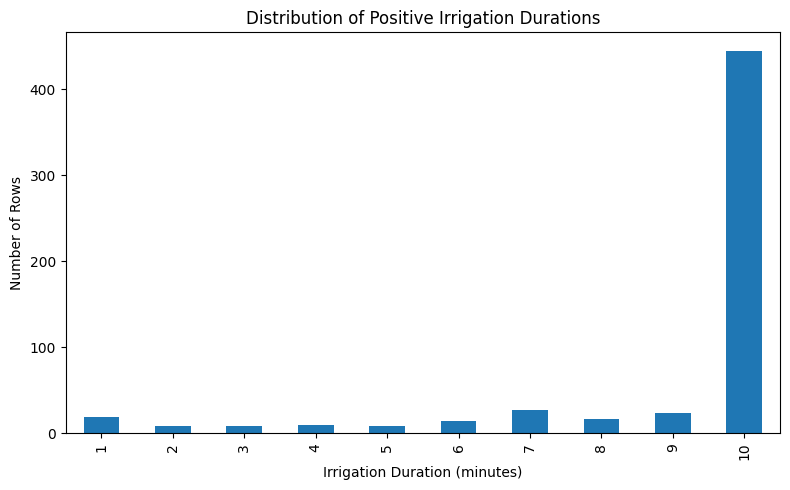

In [ ]:
import matplotlib.pyplot as plt

# Distribution of irrigation durations
print("Training irrigation duration counts:")
print(y_train[y_train > 0].value_counts().sort_index())

plt.figure(figsize=(8, 5))
y_train[y_train > 0].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Positive Irrigation Durations")
plt.xlabel("Irrigation Duration (minutes)")
plt.ylabel("Number of Rows")
plt.tight_layout()
plt.savefig("irrigation_duration_distribution.png", dpi=300)
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Count the frequency of each positive duration
counts = y_train_irrigation.value_counts()

# Give greater weight to less frequent durations
weights = y_train_irrigation.map(
    lambda value: len(y_train_irrigation) /
    (len(counts) * counts[value])
)

# Train improved model
improved_model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

improved_model.fit(
    X_train_irrigation,
    y_train_irrigation,
    sample_weight=weights
)

# Predict on the same positive irrigation test rows
improved_pred = improved_model.predict(X_test_irrigation)

print("Improved Model Results")
print("MAE:", mean_absolute_error(y_test_irrigation, improved_pred))
print("RMSE:", np.sqrt(mean_squared_error(
    y_test_irrigation, improved_pred
)))
print("R2 Score:", r2_score(y_test_irrigation, improved_pred))

print("\nPrevious Random Forest MAE:",
      mean_absolute_error(y_test_irrigation, duration_pred))

Improved Model Results
MAE: 1.226796358185506
RMSE: 1.8975205575291723
R2 Score: 0.1253486498712989

Previous Random Forest MAE: 1.0386879432624112


In [ ]:
import joblib
import pandas as pd
import numpy as np

# Save both duration models
joblib.dump(duration_model, "previous_duration_model.pkl")
joblib.dump(improved_model, "improved_duration_model.pkl")

# Compare predictions on the same test rows
comparison = pd.DataFrame({
    "Actual Duration": y_test_irrigation.to_numpy(),
    "Previous RF Prediction": duration_pred,
    "Improved RF Prediction": improved_pred
})

display(comparison.head(15))

# Save comparison results
comparison.to_csv("duration_prediction_comparison.csv", index=False)

print("Both models and comparison results saved.")

,Actual Duration,Previous RF Prediction,Improved RF Prediction
0,10,9.860,9.741765
1,8,8.620,8.186436
2,10,9.535,9.541308
3,2,9.055,8.846404
4,7,7.900,7.919747
5,10,9.995,9.829562
6,10,9.655,9.321417
7,10,9.035,8.106036
8,10,8.895,9.247332
9,10,9.210,8.576572


Both models and comparison results saved.


combine two models


In [ ]:
import numpy as np
import pandas as pd

def predict_irrigation(input_data):
    # Predict whether irrigation is needed
    event = classifier.predict(input_data)[0]

    if event == 1:
        # Predict irrigation duration
        duration = duration_model.predict(input_data)[0]
        duration = np.clip(duration, 1, 10)
    else:
        duration = 0

    return {
        "Irrigation Required": "Yes" if event == 1 else "No",
        "Predicted Duration (minutes)": round(float(duration), 2)
    }

# Test using one row from the test dataset
sample = X_test.iloc[[0]]

result = predict_irrigation(sample)

print("Precision Irrigation Prediction")
print("------------------------------")
print("Input data:")
display(sample)
print("\nPrediction:")
print(result)

Precision Irrigation Prediction
------------------------------
Input data:


,weather_temp,weather_humidity,weather_rain,weather_pressure,weather_wind_speed,weather_radiation,soil_temperature_0-7cm,soil_temperature_7-18cm,ph,hour,day,month
19752,22.0,77.625,0.0,1010.8075,8.09,0.0,24.7475,29.285,7.0,4,26,6



Prediction:
{'Irrigation Required': 'No', 'Predicted Duration (minutes)': 0.0}


In [ ]:
import joblib

joblib.dump(classifier, "irrigation_classifier.pkl")
joblib.dump(duration_model, "irrigation_duration_model.pkl")
joblib.dump(improved_model, "improved_duration_model.pkl")

print("All models saved successfully!")

All models saved successfully!


In [ ]:
from google.colab import files

files.download("irrigation_classifier.pkl")
files.download("irrigation_duration_model.pkl")
files.download("improved_duration_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

final_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "MAE": 0.118903,
        "RMSE": 0.602784,
        "R2 Score": 0.802825
    },
    {
        "Model": "XGBoost",
        "MAE": 0.313763,
        "RMSE": 1.072284,
        "R2 Score": 0.376052
    },
    {
        "Model": "SVR",
        "MAE": 0.236984,
        "RMSE": 1.351388,
        "R2 Score": 0.008966
    },
    {
        "Model": "Stacking Ensemble",
        "MAE": 0.137928,
        "RMSE": 0.573956,
        "R2 Score": 0.821234
    }
])

display(final_results)

final_results.to_csv("final_model_comparison.csv", index=False)

print("Final results table saved successfully!")

,Model,MAE,RMSE,R2 Score
0,Random Forest,0.118903,0.602784,0.802825
1,XGBoost,0.313763,1.072284,0.376052
2,SVR,0.236984,1.351388,0.008966
3,Stacking Ensemble,0.137928,0.573956,0.821234


Final results table saved successfully!


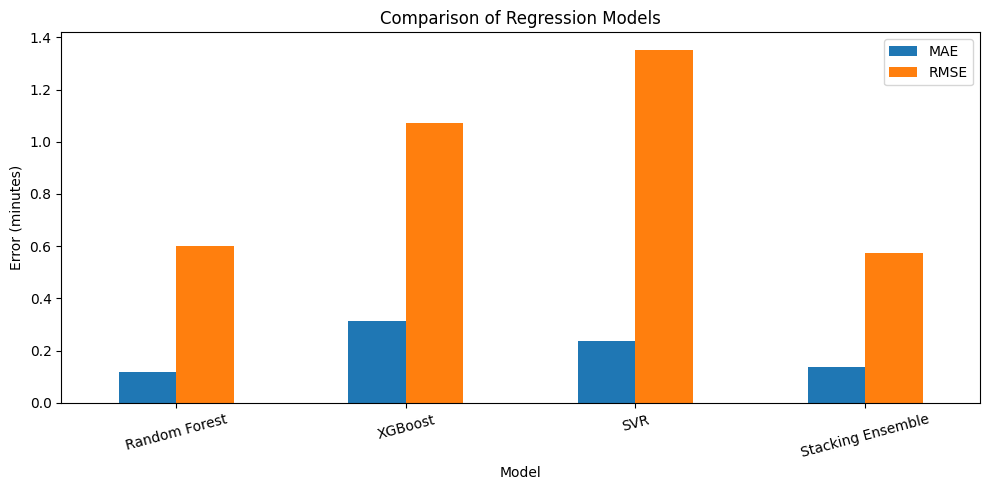

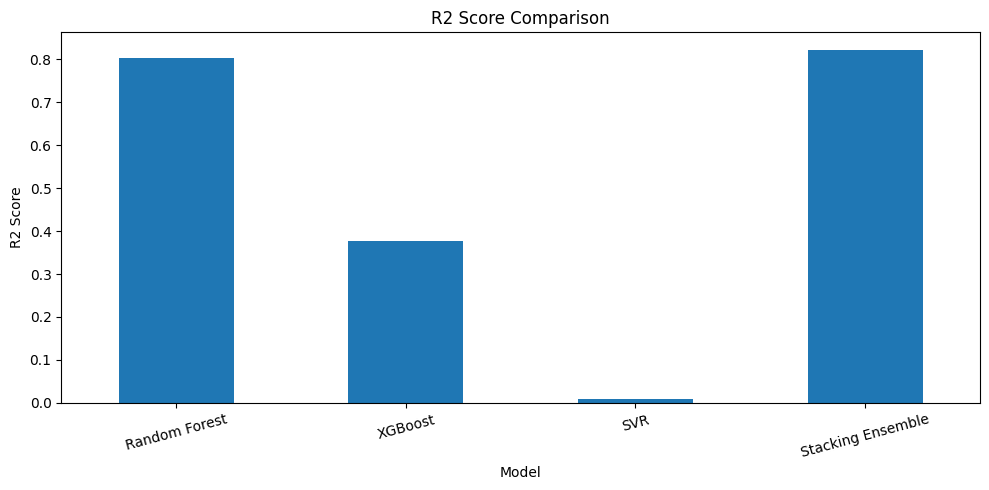

Final graphs saved successfully!


In [ ]:
import matplotlib.pyplot as plt

# MAE and RMSE comparison
final_results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar", figsize=(10, 5)
)
plt.title("Comparison of Regression Models")
plt.ylabel("Error (minutes)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("final_model_error_comparison.png", dpi=300)
plt.show()

# R2 score comparison
final_results.set_index("Model")["R2 Score"].plot(
    kind="bar", figsize=(10, 5)
)
plt.title("R2 Score Comparison")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("final_model_r2_comparison.png", dpi=300)
plt.show()

print("Final graphs saved successfully!")

In [ ]:
from google.colab import files

files.download("final_model_error_comparison.png")
files.download("final_model_r2_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_regression, RFE
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Split the existing prepared dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Three feature techniques
techniques = {
    "SelectKBest": SelectKBest(
        score_func=mutual_info_regression, k=6
    ),
    "RFE": RFE(
        estimator=RandomForestRegressor(
            n_estimators=50, random_state=42, n_jobs=-1
        ),
        n_features_to_select=6
    ),
    "PCA": PCA(n_components=0.95)
}

# Models
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBRegressor(
        n_estimators=100, max_depth=4,
        learning_rate=0.1, random_state=42, n_jobs=-1
    ),
    "SVR": SVR(),
    "Stacking Ensemble": StackingRegressor(
        estimators=[
            ("rf", RandomForestRegressor(
                n_estimators=100, random_state=42, n_jobs=-1
            )),
            ("xgb", XGBRegressor(
                n_estimators=100, max_depth=4,
                learning_rate=0.1, random_state=42, n_jobs=-1
            )),
            ("svr", SVR())
        ],
        final_estimator=Ridge(),
        cv=3
    )
}

# Train and compare
results = []

for technique_name, technique in techniques.items():
    for model_name, model in models.items():

        pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("feature_selection", clone(technique)),
            ("model", clone(model))
        ])

        pipeline.fit(X_train, y_train)
        predictions = pipeline.predict(X_test)

        results.append({
            "Feature Technique": technique_name,
            "Model": model_name,
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_test, predictions)
            ),
            "R2 Score": r2_score(y_test, predictions)
        })

comparison_df = pd.DataFrame(results).sort_values("RMSE")

print("APPROACH B: FEATURE TECHNIQUE COMPARISON")
display(comparison_df.round(4))

comparison_df.to_csv(
    "approach_b_feature_comparison.csv", index=False
)

print("Comparison completed and CSV saved.")


APPROACH B: FEATURE TECHNIQUE COMPARISON


,Feature Technique,Model,MAE,RMSE,R2 Score
3,SelectKBest,Stacking Ensemble,0.1087,0.5356,0.8443
7,RFE,Stacking Ensemble,0.1600,0.6453,0.7740
4,RFE,Random Forest,0.1384,0.6762,0.7519
11,PCA,Stacking Ensemble,0.2199,0.7703,0.6780
0,SelectKBest,Random Forest,0.1646,0.7846,0.6660
8,PCA,Random Forest,0.1796,0.8081,0.6456
5,RFE,XGBoost,0.3153,1.0649,0.3846
1,SelectKBest,XGBoost,0.3346,1.1191,0.3204
9,PCA,XGBoost,0.3406,1.1666,0.2614
10,PCA,SVR,0.2412,1.3548,0.0040


Comparison completed and CSV saved.


---

# Stage 2: Wider model set, F-test feature selection, randomized tuning and stacking

Six models compared before and after RandomizedSearchCV, then a stacking ensemble of five tuned models. Uses all columns with missing-value indicators, 10 features chosen by SelectKBest (f_regression).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("/content/dataset_zone_1.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (33259, 18)


,ts,outside_temperature,inside_temperature,outside_humidity,inside_humidity,weather_temp,weather_humidity,weather_rain,weather_pressure,weather_wind_speed,weather_radiation,soil_temperature_0-7cm,soil_temperature_7-18cm,ec,ph,soil_moisture,irrigation_duration_minutes,liters_total
0,2025-02-09 00:00:00,NaN,NaN,NaN,NaN,5.7775,91.0,0.0,1025.785000,5.960000,0.0,7.670000,10.785000,NaN,NaN,NaN,0,0.0
1,2025-02-09 00:10:00,NaN,NaN,NaN,NaN,5.7275,91.0,0.0,1025.751667,6.093333,0.0,7.603333,10.751667,NaN,NaN,NaN,0,0.0
2,2025-02-09 00:20:00,NaN,NaN,NaN,NaN,5.6775,91.0,0.0,1025.718333,6.226667,0.0,7.536667,10.718333,NaN,NaN,NaN,0,0.0
3,2025-02-09 00:30:00,NaN,NaN,NaN,NaN,5.6275,91.0,0.0,1025.685000,6.360000,0.0,7.470000,10.685000,NaN,NaN,NaN,0,0.0
4,2025-02-09 00:40:00,NaN,NaN,NaN,NaN,5.5775,91.0,0.0,1025.651667,6.493333,0.0,7.403333,10.651667,NaN,NaN,NaN,0,0.0


In [ ]:
# STEP 3: DATA PREPROCESSING

df_clean = df.copy()

# Target column
target = "irrigation_duration_minutes"

# Check target column
if target not in df_clean.columns:
    print("Available columns:", df_clean.columns.tolist())
    raise ValueError("Target column not found!")

# Remove completely empty columns
df_clean = df_clean.dropna(axis=1, how="all")

# Convert target into numeric values
df_clean[target] = pd.to_numeric(
    df_clean[target],
    errors="coerce"
)

# Remove rows with missing target values
df_clean = df_clean.dropna(subset=[target])

# Convert timestamp into useful features
if "ts" in df_clean.columns:

    df_clean["ts"] = pd.to_datetime(
        df_clean["ts"],
        errors="coerce"
    )

    df_clean["hour"] = df_clean["ts"].dt.hour
    df_clean["day"] = df_clean["ts"].dt.day
    df_clean["month"] = df_clean["ts"].dt.month
    df_clean["day_of_week"] = df_clean["ts"].dt.dayofweek

    df_clean = df_clean.drop(columns=["ts"])

# Handle negative soil moisture
if "soil_moisture" in df_clean.columns:

    df_clean.loc[
        df_clean["soil_moisture"] < 0,
        "soil_moisture"
    ] = np.nan

# Add missing value indicators
for col in ["soil_moisture", "ec", "ph"]:

    if col in df_clean.columns:

        df_clean[col + "_missing"] = (
            df_clean[col].isnull().astype(int)
        )

# Remove liters_total column if present
df_clean = df_clean.drop(
    columns=["liters_total"],
    errors="ignore"
)

print("Data preprocessing completed!")

print("Cleaned Dataset Shape:", df_clean.shape)

display(df_clean.head())

Data preprocessing completed!
Cleaned Dataset Shape: (33259, 23)


,outside_temperature,inside_temperature,outside_humidity,inside_humidity,weather_temp,weather_humidity,weather_rain,weather_pressure,weather_wind_speed,weather_radiation,...,ph,soil_moisture,irrigation_duration_minutes,hour,day,month,day_of_week,soil_moisture_missing,ec_missing,ph_missing
0,NaN,NaN,NaN,NaN,5.7775,91.0,0.0,1025.785000,5.960000,0.0,...,NaN,NaN,0,0,9,2,6,1,1,1
1,NaN,NaN,NaN,NaN,5.7275,91.0,0.0,1025.751667,6.093333,0.0,...,NaN,NaN,0,0,9,2,6,1,1,1
2,NaN,NaN,NaN,NaN,5.6775,91.0,0.0,1025.718333,6.226667,0.0,...,NaN,NaN,0,0,9,2,6,1,1,1
3,NaN,NaN,NaN,NaN,5.6275,91.0,0.0,1025.685000,6.360000,0.0,...,NaN,NaN,0,0,9,2,6,1,1,1
4,NaN,NaN,NaN,NaN,5.5775,91.0,0.0,1025.651667,6.493333,0.0,...,NaN,NaN,0,0,9,2,6,1,1,1


In [ ]:
# STEP 4: SEPARATE FEATURES AND TARGET

X = df_clean.drop(columns=["irrigation_duration_minutes"])

y = df_clean["irrigation_duration_minutes"]

# Convert features into numeric values
X = X.apply(pd.to_numeric, errors="coerce")

# Remove completely empty columns
X = X.dropna(axis=1, how="all")

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput columns:")
print(X.columns.tolist())

Input features shape: (33259, 22)
Target shape: (33259,)

Input columns:
['outside_temperature', 'inside_temperature', 'outside_humidity', 'inside_humidity', 'weather_temp', 'weather_humidity', 'weather_rain', 'weather_pressure', 'weather_wind_speed', 'weather_radiation', 'soil_temperature_0-7cm', 'soil_temperature_7-18cm', 'ec', 'ph', 'soil_moisture', 'hour', 'day', 'month', 'day_of_week', 'soil_moisture_missing', 'ec_missing', 'ph_missing']


In [ ]:

# STEP 5: SPLIT DATASET INTO TRAINING AND TESTING SETS

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Handle missing values
imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training features shape: (26607, 22)
Testing features shape: (6652, 22)
Training target shape: (26607,)
Testing target shape: (6652,)


In [ ]:

# STEP 6: FEATURE SELECTION

from sklearn.feature_selection import SelectKBest, f_regression

# Select top 10 features
selector = SelectKBest(score_func=f_regression, k=10)

X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

selected_features = X_train.columns[selector.get_support()]

print("Selected Features:")
print(selected_features.tolist())

print("\nTraining shape:", X_train_selected.shape)
print("Testing shape:", X_test_selected.shape)


Selected Features:
['weather_temp', 'weather_humidity', 'weather_wind_speed', 'weather_radiation', 'soil_temperature_0-7cm', 'ec', 'ph', 'soil_moisture', 'day', 'ph_missing']

Training shape: (26607, 10)
Testing shape: (6652, 10)


In [ ]:

# STEP 7: TRAIN MACHINE LEARNING MODELS

import numpy as np
import pandas as pd

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Define models
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    ),

    "AdaBoost": AdaBoostRegressor(
        n_estimators=100,
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        random_state=42
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=100,
        random_state=42
    ),

    "SVR": make_pipeline(
        StandardScaler(),
        SVR(kernel='rbf')
    )
}

# Store model results
results = []

# Train and evaluate each model
for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train_selected, y_train)

    y_pred = model.predict(X_test_selected)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2 Score:", r2)

# Display results
results_df = pd.DataFrame(results)

print("\n===== MODEL PERFORMANCE COMPARISON =====")
display(results_df)



Training: Random Forest
MAE: 0.20462717979555017
RMSE: 0.8792259688324684
R2 Score: 0.5805022277992964

Training: Gradient Boosting
MAE: 0.34822307071814046
RMSE: 1.229956504051812
R2 Score: 0.17906617230229682

Training: AdaBoost
MAE: 0.3708685972869435
RMSE: 1.3432531872808842
R2 Score: 0.02086087567349293

Training: Extra Trees
MAE: 0.17628232110643416
RMSE: 0.7803053910535772
R2 Score: 0.6695864418721668

Training: Hist Gradient Boosting
MAE: 0.25058775205258066
RMSE: 0.9395132661253648
R2 Score: 0.5210011413979522

Training: SVR
MAE: 0.2502345510106295
RMSE: 1.3558959638998624
R2 Score: 0.002342708804600968

===== MODEL PERFORMANCE COMPARISON =====


,Model,MAE,RMSE,R2 Score
0,Random Forest,0.204627,0.879226,0.580502
1,Gradient Boosting,0.348223,1.229957,0.179066
2,AdaBoost,0.370869,1.343253,0.020861
3,Extra Trees,0.176282,0.780305,0.669586
4,Hist Gradient Boosting,0.250588,0.939513,0.521001
5,SVR,0.250235,1.355896,0.002343


In [ ]:

# STEP 8: COMPARE MODEL PERFORMANCE

results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
)

print("===== BEST PERFORMING MODEL =====")

display(results_df)

best_model_name = results_df.iloc[0]["Model"]

print("Best Model:", best_model_name)


===== BEST PERFORMING MODEL =====


,Model,MAE,RMSE,R2 Score
3,Extra Trees,0.176282,0.780305,0.669586
0,Random Forest,0.204627,0.879226,0.580502
4,Hist Gradient Boosting,0.250588,0.939513,0.521001
1,Gradient Boosting,0.348223,1.229957,0.179066
2,AdaBoost,0.370869,1.343253,0.020861
5,SVR,0.250235,1.355896,0.002343


Best Model: Extra Trees


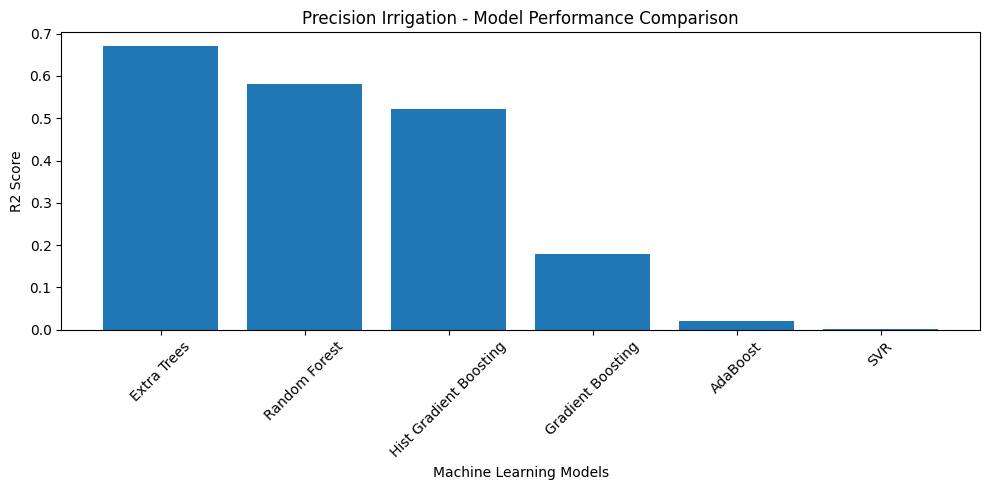

In [ ]:

# STEP 9: MODEL PERFORMANCE VISUALIZATION

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["R2 Score"]
)

plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")
plt.title("Precision Irrigation - Model Performance Comparison")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


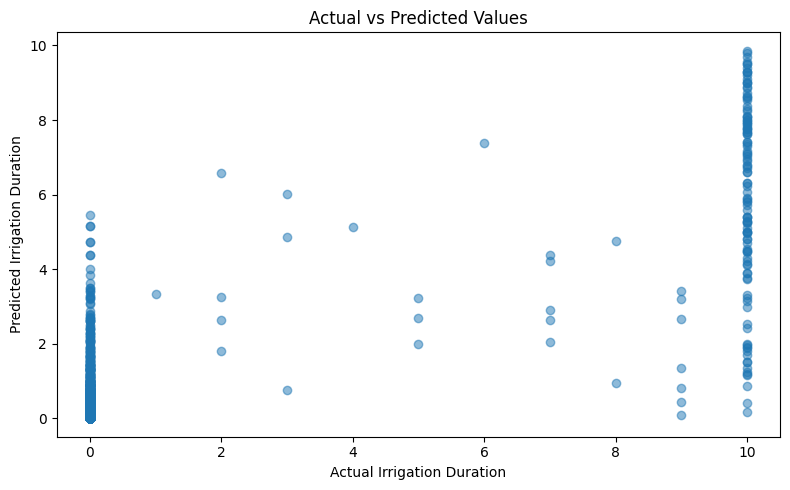

Best Model: Extra Trees


In [ ]:

# STEP 10: ACTUAL VS PREDICTED VALUES

import matplotlib.pyplot as plt

# Get the best trained model
best_model = models[best_model_name]

# Predict test data
y_pred = best_model.predict(X_test_selected)

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Irrigation Duration")
plt.ylabel("Predicted Irrigation Duration")
plt.title("Actual vs Predicted Values")

plt.tight_layout()
plt.show()

print("Best Model:", best_model_name)


Mean Error: -0.011640108238123871
Maximum Error: 9.82
Minimum Error: -5.46
Mean Absolute Error: 0.17628232110643416


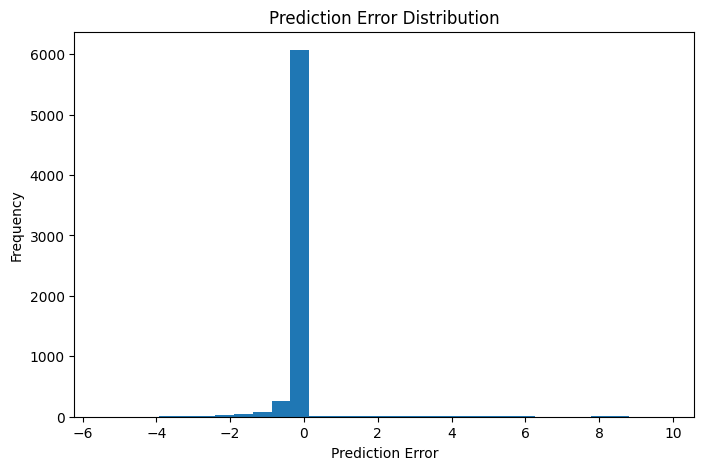

In [ ]:

# STEP 11: ERROR ANALYSIS

errors = y_test - y_pred

print("Mean Error:", errors.mean())
print("Maximum Error:", errors.max())
print("Minimum Error:", errors.min())
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))

plt.figure(figsize=(8, 5))

plt.hist(errors, bins=30)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Prediction Error Distribution")

plt.show()


In [ ]:

# STEP 12: SAVE BEST MODEL

import joblib

model_package = {
    "model": best_model,
    "imputer": imputer,
    "selector": selector,
    "feature_columns": X.columns.tolist(),
    "selected_features": selected_features.tolist()
}

joblib.dump(model_package, "precision_irrigation_model.pkl")

print("Best Model:", best_model_name)
print("Model saved successfully!")
print("File: precision_irrigation_model.pkl")


Best Model: Extra Trees
Model saved successfully!
File: precision_irrigation_model.pkl


In [ ]:

# STEP 13: NEW IRRIGATION PREDICTION

# Create sample input
new_input = pd.DataFrame(
    [X.median(numeric_only=True).to_dict()]
)

# Apply preprocessing
new_input_imputed = imputer.transform(new_input)

# Select important features
new_input_selected = selector.transform(new_input_imputed)

# Predict irrigation duration
predicted_duration = best_model.predict(new_input_selected)

print("===== IRRIGATION PREDICTION =====")
print("Predicted Irrigation Duration:",
      round(predicted_duration[0], 2), "minutes")


===== IRRIGATION PREDICTION =====
Predicted Irrigation Duration: 0.19 minutes


In [ ]:

# STEP 14: FINAL PROJECT SUMMARY

print("========================================")
print("       PRECISION IRRIGATION SYSTEM")
print("========================================")

print("Dataset Records:", len(df))
print("Input Features:", X.shape[1])
print("Selected Features:", len(selected_features))
print("Machine Learning Models:", len(models))

print("\nBest Performing Model:", best_model_name)

print("\nModel Evaluation:")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

print("\nModel saved as: precision_irrigation_model.pkl")

print("\nProject Completed Successfully!")
print("========================================")


       PRECISION IRRIGATION SYSTEM
Dataset Records: 33259
Input Features: 22
Selected Features: 10
Machine Learning Models: 6

Best Performing Model: Extra Trees

Model Evaluation:
MAE: 0.17628232110643416
RMSE: 0.7803053910535772
R2 Score: 0.6695864418721668

Model saved as: precision_irrigation_model.pkl

Project Completed Successfully!


In [ ]:

# STEP 15: SAVE BEFORE HYPERPARAMETER TUNING RESULTS

before_tuning = results_df.copy()

print("===== BEFORE HYPERPARAMETER TUNING =====")
display(before_tuning)

print("Original model results saved successfully!")
print("Random State: 42")


===== BEFORE HYPERPARAMETER TUNING =====


,Model,MAE,RMSE,R2 Score
3,Extra Trees,0.176282,0.780305,0.669586
0,Random Forest,0.204627,0.879226,0.580502
4,Hist Gradient Boosting,0.250588,0.939513,0.521001
1,Gradient Boosting,0.348223,1.229957,0.179066
2,AdaBoost,0.370869,1.343253,0.020861
5,SVR,0.250235,1.355896,0.002343


Original model results saved successfully!
Random State: 42


In [ ]:

# STEP 16: FAST HYPERPARAMETER TUNING

from sklearn.model_selection import RandomizedSearchCV

RANDOM_STATE = 42

tuning_models = {

    "Random Forest": (
        RandomForestRegressor(random_state=42, n_jobs=1),
        {
            "n_estimators": [50, 100],
            "max_depth": [10, 20, None],
            "min_samples_split": [2, 5]
        }
    ),

    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=42),
        {
            "n_estimators": [50, 100],
            "learning_rate": [0.05, 0.1],
            "max_depth": [2, 3]
        }
    ),

    "AdaBoost": (
        AdaBoostRegressor(random_state=42),
        {
            "n_estimators": [50, 100],
            "learning_rate": [0.05, 0.1, 1.0]
        }
    ),

    "Extra Trees": (
        ExtraTreesRegressor(random_state=42, n_jobs=1),
        {
            "n_estimators": [50, 100],
            "max_depth": [10, 20, None],
            "min_samples_split": [2, 5]
        }
    ),

    "Hist Gradient Boosting": (
        HistGradientBoostingRegressor(random_state=42),
        {
            "max_iter": [50, 100],
            "learning_rate": [0.05, 0.1],
            "max_leaf_nodes": [15, 31]
        }
    )
}

best_models = {}
tuning_results = []

for name, (model, params) in tuning_models.items():

    print("\nTuning:", name)

    random_search = RandomizedSearchCV(
        estimator=model,
        param_distributions=params,
        n_iter=3,
        cv=2,
        scoring="neg_mean_absolute_error",
        random_state=42,
        n_jobs=-1,
        verbose=1
    )

    random_search.fit(X_train_selected, y_train)

    best_model = random_search.best_estimator_
    best_models[name] = best_model

    y_pred_tuned = best_model.predict(X_test_selected)

    mae = mean_absolute_error(y_test, y_pred_tuned)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
    r2 = r2_score(y_test, y_pred_tuned)

    tuning_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2,
        "Best Parameters": random_search.best_params_
    })

    print("Best Parameters:", random_search.best_params_)
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2 Score:", r2)

after_tuning = pd.DataFrame(tuning_results)

print("\n===== AFTER HYPERPARAMETER TUNING =====")
display(after_tuning)



Tuning: Random Forest
Fitting 2 folds for each of 3 candidates, totalling 6 fits
Best Parameters: {'n_estimators': 100, 'min_samples_split': 2, 'max_depth': None}
MAE: 0.20462717979555017
RMSE: 0.8792259688324684
R2 Score: 0.5805022277992964

Tuning: Gradient Boosting
Fitting 2 folds for each of 3 candidates, totalling 6 fits
Best Parameters: {'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.05}
MAE: 0.3613330913737709
RMSE: 1.3142529799522176
R2 Score: 0.06268280162633577

Tuning: AdaBoost
Fitting 2 folds for each of 3 candidates, totalling 6 fits
Best Parameters: {'n_estimators': 100, 'learning_rate': 1.0}
MAE: 0.3708685972869435
RMSE: 1.3432531872808842
R2 Score: 0.02086087567349293

Tuning: Extra Trees
Fitting 2 folds for each of 3 candidates, totalling 6 fits
Best Parameters: {'n_estimators': 100, 'min_samples_split': 2, 'max_depth': None}
MAE: 0.17628232110643416
RMSE: 0.7803053910535772
R2 Score: 0.6695864418721668

Tuning: Hist Gradient Boosting
Fitting 2 folds for each

,Model,MAE,RMSE,R2 Score,Best Parameters
0,Random Forest,0.204627,0.879226,0.580502,"{'n_estimators': 100, 'min_samples_split': 2, ..."
1,Gradient Boosting,0.361333,1.314253,0.062683,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
2,AdaBoost,0.370869,1.343253,0.020861,"{'n_estimators': 100, 'learning_rate': 1.0}"
3,Extra Trees,0.176282,0.780305,0.669586,"{'n_estimators': 100, 'min_samples_split': 2, ..."
4,Hist Gradient Boosting,0.258623,1.015171,0.440748,"{'max_leaf_nodes': 31, 'max_iter': 50, 'learni..."


In [ ]:

# STEP 17: BEFORE AND AFTER HYPERPARAMETER TUNING

# Merge before and after results
comparison = before_tuning.merge(
    after_tuning,
    on="Model",
    suffixes=("_Before", "_After")
)

# Calculate improvements
comparison["MAE Improvement (%)"] = (
    (comparison["MAE_Before"] - comparison["MAE_After"])
    / comparison["MAE_Before"].replace(0, np.nan)
) * 100

comparison["RMSE Improvement (%)"] = (
    (comparison["RMSE_Before"] - comparison["RMSE_After"])
    / comparison["RMSE_Before"].replace(0, np.nan)
) * 100

comparison["R2 Improvement"] = (
    comparison["R2 Score_After"] -
    comparison["R2 Score_Before"]
)

# Display comparison
print("===== BEFORE VS AFTER HYPERPARAMETER TUNING =====")

display(comparison[[
    "Model",
    "MAE_Before",
    "MAE_After",
    "RMSE_Before",
    "RMSE_After",
    "R2 Score_Before",
    "R2 Score_After",
    "MAE Improvement (%)",
    "RMSE Improvement (%)",
    "R2 Improvement"
]].round(4))


===== BEFORE VS AFTER HYPERPARAMETER TUNING =====


,Model,MAE_Before,MAE_After,RMSE_Before,RMSE_After,R2 Score_Before,R2 Score_After,MAE Improvement (%),RMSE Improvement (%),R2 Improvement
0,Extra Trees,0.1763,0.1763,0.7803,0.7803,0.6696,0.6696,0.0000,0.0000,0.0000
1,Random Forest,0.2046,0.2046,0.8792,0.8792,0.5805,0.5805,0.0000,0.0000,0.0000
2,Hist Gradient Boosting,0.2506,0.2586,0.9395,1.0152,0.5210,0.4407,-3.2065,-8.0529,-0.0803
3,Gradient Boosting,0.3482,0.3613,1.2300,1.3143,0.1791,0.0627,-3.7648,-6.8536,-0.1164
4,AdaBoost,0.3709,0.3709,1.3433,1.3433,0.0209,0.0209,0.0000,0.0000,0.0000


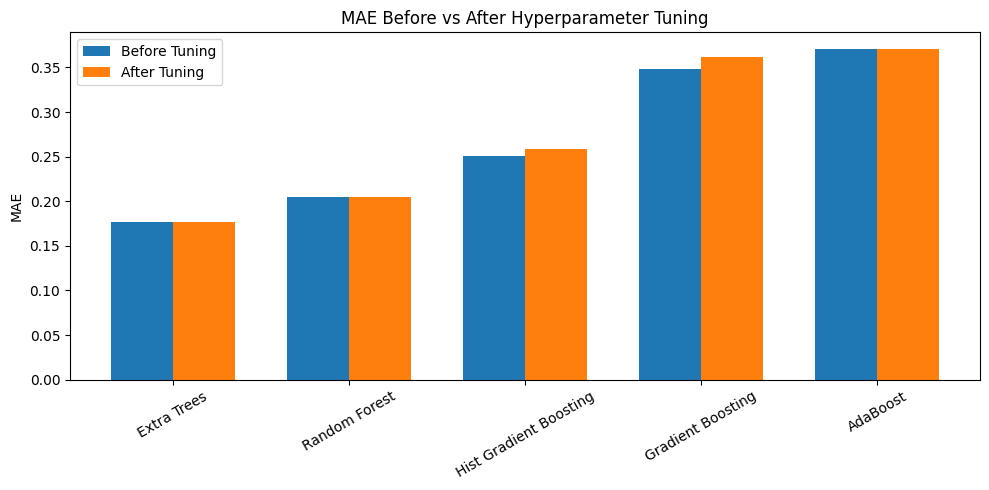

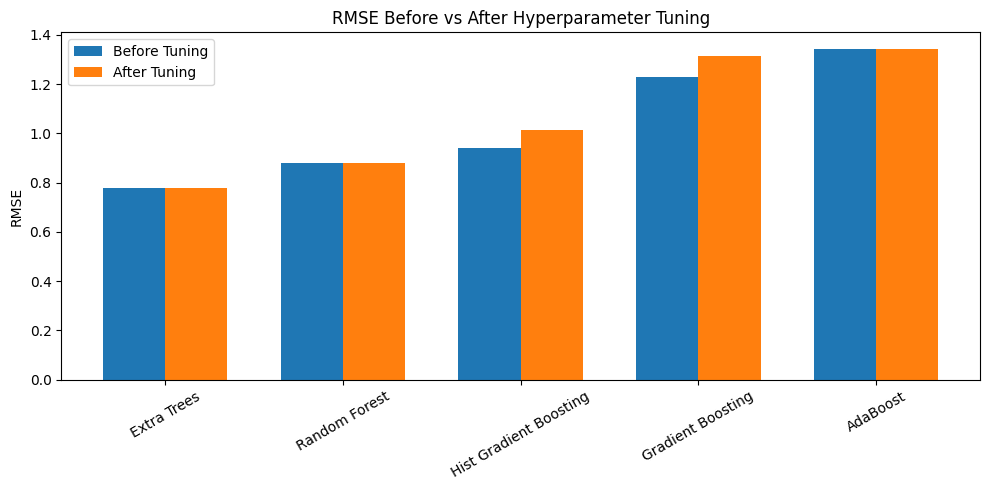

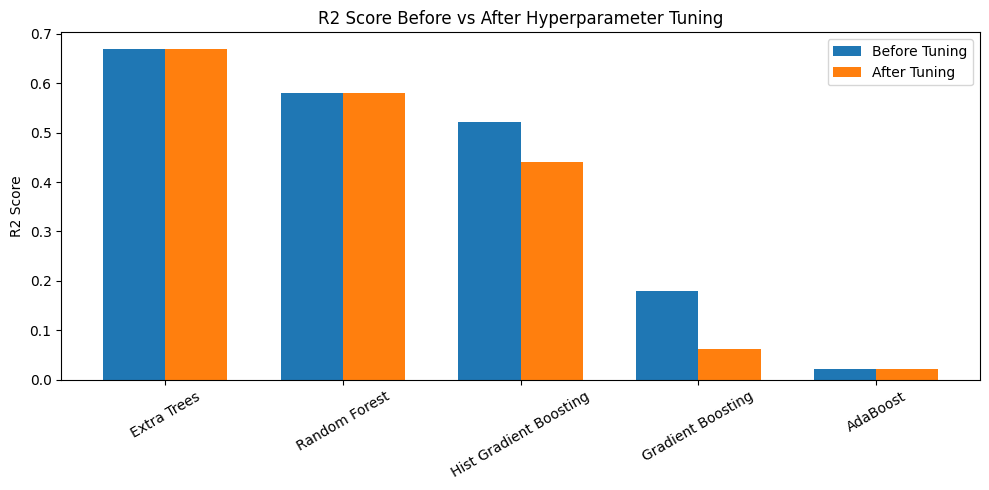

In [ ]:

# STEP 18: PERFORMANCE COMPARISON GRAPH

import matplotlib.pyplot as plt

metrics = ["MAE", "RMSE", "R2 Score"]

for metric in metrics:

    plt.figure(figsize=(10, 5))

    x = np.arange(len(comparison))
    width = 0.35

    plt.bar(
        x - width/2,
        comparison[metric + "_Before"],
        width,
        label="Before Tuning"
    )

    plt.bar(
        x + width/2,
        comparison[metric + "_After"],
        width,
        label="After Tuning"
    )

    plt.xticks(x, comparison["Model"], rotation=30)
    plt.ylabel(metric)
    plt.title(metric + " Before vs After Hyperparameter Tuning")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:

# STEP 19: IDENTIFY BEST TUNED MODEL

best_index = after_tuning["R2 Score"].idxmax()

best_tuned_name = after_tuning.loc[best_index, "Model"]

best_tuned_model = best_models[best_tuned_name]

print("===== BEST TUNED MODEL =====")
print("Model:", best_tuned_name)
print("MAE:", after_tuning.loc[best_index, "MAE"])
print("RMSE:", after_tuning.loc[best_index, "RMSE"])
print("R2 Score:", after_tuning.loc[best_index, "R2 Score"])


===== BEST TUNED MODEL =====
Model: Extra Trees
MAE: 0.17628232110643416
RMSE: 0.7803053910535772
R2 Score: 0.6695864418721668


In [ ]:

# STEP 20: STACKING HYBRID MODEL

from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge
from sklearn.base import clone

# Select the tuned base models
base_estimators = [
    ("random_forest", clone(best_models["Random Forest"])),
    ("gradient_boosting", clone(best_models["Gradient Boosting"])),
    ("adaboost", clone(best_models["AdaBoost"])),
    ("extra_trees", clone(best_models["Extra Trees"])),
    ("hist_gradient_boosting",
     clone(best_models["Hist Gradient Boosting"]))
]

# Create stacking model
stacking_model = StackingRegressor(
    estimators=base_estimators,
    final_estimator=Ridge(alpha=1.0),
    cv=3,
    passthrough=False,
    n_jobs=-1
)

# Train stacking model
print("Training Stacking Hybrid Model...")

stacking_model.fit(X_train_selected, y_train)

# Predict
stacking_predictions = stacking_model.predict(X_test_selected)

# Evaluate
stack_mae = mean_absolute_error(
    y_test, stacking_predictions
)

stack_rmse = np.sqrt(
    mean_squared_error(y_test, stacking_predictions)
)

stack_r2 = r2_score(
    y_test, stacking_predictions
)

print("\n===== STACKING HYBRID MODEL RESULTS =====")
print("MAE:", stack_mae)
print("RMSE:", stack_rmse)
print("R2 Score:", stack_r2)


Training Stacking Hybrid Model...

===== STACKING HYBRID MODEL RESULTS =====
MAE: 0.19259174506892965
RMSE: 0.7468314112265918
R2 Score: 0.6973269197501002


In [ ]:

# STEP 21: COMPLETE MODEL COMPARISON

all_results = []

# Before tuning models
for _, row in before_tuning.iterrows():

    all_results.append({
        "Model": row["Model"],
        "Category": "Before Tuning",
        "MAE": row["MAE"],
        "RMSE": row["RMSE"],
        "R2 Score": row["R2 Score"]
    })

# After tuning models
for _, row in after_tuning.iterrows():

    all_results.append({
        "Model": row["Model"],
        "Category": "After Tuning",
        "MAE": row["MAE"],
        "RMSE": row["RMSE"],
        "R2 Score": row["R2 Score"]
    })

# Stacking hybrid model
all_results.append({
    "Model": "Stacking Regressor",
    "Category": "Hybrid Model",
    "MAE": stack_mae,
    "RMSE": stack_rmse,
    "R2 Score": stack_r2
})

# Create final comparison table
final_comparison = pd.DataFrame(all_results)

final_comparison = final_comparison.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

print("===== COMPLETE MODEL PERFORMANCE COMPARISON =====")

display(final_comparison.round(4))


===== COMPLETE MODEL PERFORMANCE COMPARISON =====


,Model,Category,MAE,RMSE,R2 Score
0,Stacking Regressor,Hybrid Model,0.1926,0.7468,0.6973
1,Extra Trees,Before Tuning,0.1763,0.7803,0.6696
2,Extra Trees,After Tuning,0.1763,0.7803,0.6696
3,Random Forest,Before Tuning,0.2046,0.8792,0.5805
4,Random Forest,After Tuning,0.2046,0.8792,0.5805
5,Hist Gradient Boosting,Before Tuning,0.2506,0.9395,0.5210
6,Hist Gradient Boosting,After Tuning,0.2586,1.0152,0.4407
7,Gradient Boosting,Before Tuning,0.3482,1.2300,0.1791
8,Gradient Boosting,After Tuning,0.3613,1.3143,0.0627
9,AdaBoost,Before Tuning,0.3709,1.3433,0.0209


In [ ]:

# STEP 22: SELECT FINAL BEST MODEL

best_row = final_comparison.iloc[0]

best_model_name = best_row["Model"]
best_category = best_row["Category"]

# Select the corresponding trained model
if best_category == "Before Tuning":
    final_best_model = models[best_model_name]

elif best_category == "After Tuning":
    final_best_model = best_models[best_model_name]

else:
    final_best_model = stacking_model

print("======================================")
print("          FINAL BEST MODEL")
print("======================================")

print("Model:", best_model_name)
print("Category:", best_category)
print("MAE:", best_row["MAE"])
print("RMSE:", best_row["RMSE"])
print("R2 Score:", best_row["R2 Score"])

print("======================================")


          FINAL BEST MODEL
Model: Stacking Regressor
Category: Hybrid Model
MAE: 0.19259174506892965
RMSE: 0.7468314112265918
R2 Score: 0.6973269197501002


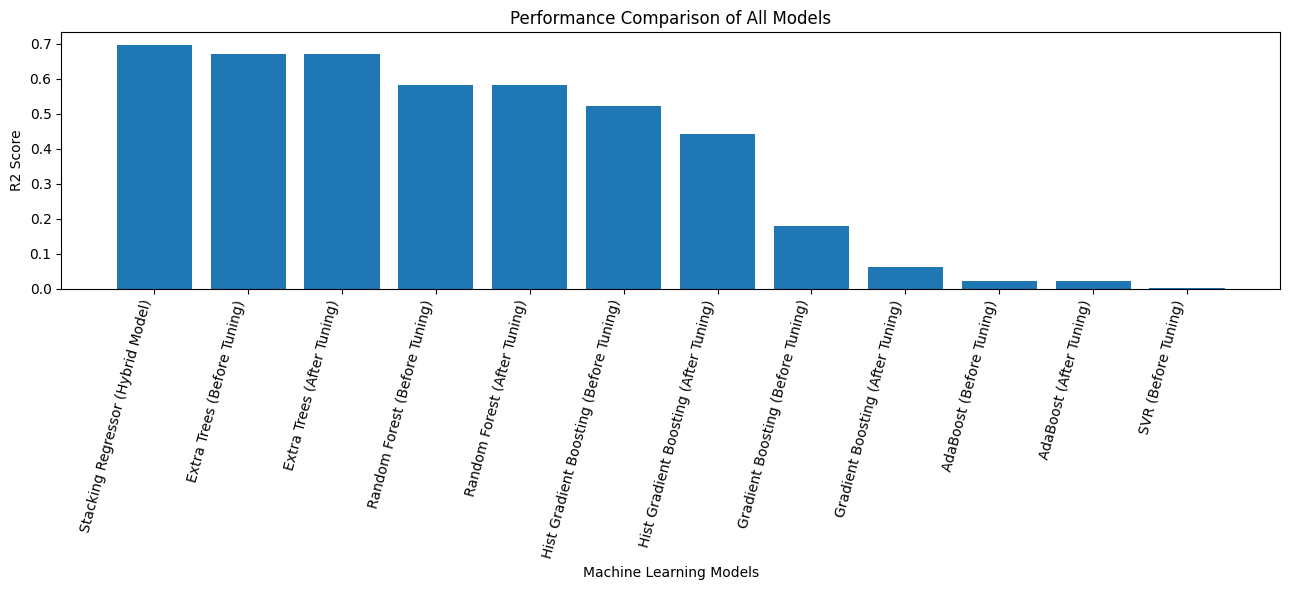

In [ ]:

# STEP 23: FINAL MODEL COMPARISON GRAPH

import matplotlib.pyplot as plt

plt.figure(figsize=(13, 6))

plt.bar(
    final_comparison["Model"] + " (" +
    final_comparison["Category"] + ")",
    final_comparison["R2 Score"]
)

plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")
plt.title("Performance Comparison of All Models")

plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 24: SAVE FINAL BEST MODEL

import joblib

final_model_package = {
    "model": final_best_model,
    "model_name": best_model_name,
    "model_category": best_category,
    "imputer": imputer,
    "selector": selector,
    "feature_columns": X.columns.tolist(),
    "selected_features": selected_features.tolist(),
    "random_state": 42
}

joblib.dump(
    final_model_package,
    "final_precision_irrigation_model.pkl"
)

print("Final Best Model Saved Successfully!")
print("File: final_precision_irrigation_model.pkl")
print("Best Model:", best_model_name)


Final Best Model Saved Successfully!
File: final_precision_irrigation_model.pkl
Best Model: Stacking Regressor


In [ ]:

# STEP 25: FINAL IRRIGATION PREDICTION

# Create sample input from dataset median values
new_input = X.median(numeric_only=True).to_frame().T

# Ensure original feature order
new_input = new_input.reindex(columns=X.columns)

# Apply preprocessing
new_input_imputed = imputer.transform(new_input)

# Apply feature selection
new_input_selected = selector.transform(new_input_imputed)

# Predict using final best model
final_prediction = final_best_model.predict(
    new_input_selected
)

print("===== FINAL IRRIGATION PREDICTION =====")
print("Best Model:", best_model_name)

print(
    "Predicted Irrigation Duration:",
    round(final_prediction[0], 2),
    "minutes"
)


===== FINAL IRRIGATION PREDICTION =====
Best Model: Stacking Regressor
Predicted Irrigation Duration: 0.18 minutes


---

# Stage 3: Grid search and prediction-time measurement

GridSearchCV over 135 parameter combinations (27 per model x 5 models), final test comparison and prediction time.


In [ ]:
from google.colab import files


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.impute import SimpleImputer

from sklearn.feature_selection import SelectKBest, f_regression

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("/content/dataset_zone_1.csv")

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (33259, 18)


,ts,outside_temperature,inside_temperature,outside_humidity,inside_humidity,weather_temp,weather_humidity,weather_rain,weather_pressure,weather_wind_speed,weather_radiation,soil_temperature_0-7cm,soil_temperature_7-18cm,ec,ph,soil_moisture,irrigation_duration_minutes,liters_total
0,2025-02-09 00:00:00,NaN,NaN,NaN,NaN,5.7775,91.0,0.0,1025.785000,5.960000,0.0,7.670000,10.785000,NaN,NaN,NaN,0,0.0
1,2025-02-09 00:10:00,NaN,NaN,NaN,NaN,5.7275,91.0,0.0,1025.751667,6.093333,0.0,7.603333,10.751667,NaN,NaN,NaN,0,0.0
2,2025-02-09 00:20:00,NaN,NaN,NaN,NaN,5.6775,91.0,0.0,1025.718333,6.226667,0.0,7.536667,10.718333,NaN,NaN,NaN,0,0.0
3,2025-02-09 00:30:00,NaN,NaN,NaN,NaN,5.6275,91.0,0.0,1025.685000,6.360000,0.0,7.470000,10.685000,NaN,NaN,NaN,0,0.0
4,2025-02-09 00:40:00,NaN,NaN,NaN,NaN,5.5775,91.0,0.0,1025.651667,6.493333,0.0,7.403333,10.651667,NaN,NaN,NaN,0,0.0


In [ ]:
df_clean = df.copy()

target = "irrigation_duration_minutes"

df_clean = df_clean.dropna(axis=1, how="all")

df_clean[target] = pd.to_numeric(
    df_clean[target],
    errors="coerce"
)

df_clean = df_clean.dropna(subset=[target])

if "ts" in df_clean.columns:

    df_clean["ts"] = pd.to_datetime(
        df_clean["ts"],
        errors="coerce"
    )

    df_clean["hour"] = df_clean["ts"].dt.hour
    df_clean["day"] = df_clean["ts"].dt.day
    df_clean["month"] = df_clean["ts"].dt.month
    df_clean["day_of_week"] = df_clean["ts"].dt.dayofweek

    df_clean = df_clean.drop(columns=["ts"])

if "soil_moisture" in df_clean.columns:

    df_clean.loc[
        df_clean["soil_moisture"] < 0,
        "soil_moisture"
    ] = np.nan

for col in ["soil_moisture", "ec", "ph"]:

    if col in df_clean.columns:

        df_clean[col + "_missing"] = (
            df_clean[col].isnull().astype(int)
        )

df_clean = df_clean.drop(
    columns=["liters_total"],
    errors="ignore"
)

print("Data preprocessing completed!")

print("Cleaned Dataset Shape:", df_clean.shape)

Data preprocessing completed!
Cleaned Dataset Shape: (33259, 23)


In [ ]:
X = df_clean.drop(columns=[target])

y = df_clean[target]

X = X.apply(pd.to_numeric, errors="coerce")

X = X.dropna(axis=1, how="all")

print("Input Features Shape:", X.shape)

print("Target Shape:", y.shape)

Input Features Shape: (33259, 22)
Target Shape: (33259,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns
)

print("Training Shape:", X_train.shape)

print("Testing Shape:", X_test.shape)

print("Training Target:", y_train.shape)

print("Testing Target:", y_test.shape)

Training Shape: (26607, 22)
Testing Shape: (6652, 22)
Training Target: (26607,)
Testing Target: (6652,)


In [ ]:
selector = SelectKBest(
    score_func=f_regression,
    k=min(10, X_train.shape[1])
)

X_train_selected = selector.fit_transform(
    X_train,
    y_train
)

X_test_selected = selector.transform(X_test)

selected_features = X_train.columns[
    selector.get_support()
]

print("Selected Features:")

print(selected_features.tolist())

print("Training Selected Shape:", X_train_selected.shape)

print("Testing Selected Shape:", X_test_selected.shape)

Selected Features:
['weather_temp', 'weather_humidity', 'weather_wind_speed', 'weather_radiation', 'soil_temperature_0-7cm', 'ec', 'ph', 'soil_moisture', 'day', 'ph_missing']
Training Selected Shape: (26607, 10)
Testing Selected Shape: (6652, 10)


In [ ]:
tuning_models = {

    "Random Forest": (
        RandomForestRegressor(random_state=42, n_jobs=1),
        {
            "n_estimators": [50, 100, 150],
            "max_depth": [5, 10, 20],
            "min_samples_split": [2, 5, 10]
        }
    ),

    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=42),
        {
            "n_estimators": [50, 100, 150],
            "learning_rate": [0.01, 0.05, 0.1],
            "max_depth": [2, 3, 5]
        }
    ),

    "AdaBoost": (
        AdaBoostRegressor(random_state=42),
        {
            "n_estimators": [50, 100, 150],
            "learning_rate": [0.01, 0.1, 1.0],
            "loss": ["linear", "square", "exponential"]
        }
    ),

    "Extra Trees": (
        ExtraTreesRegressor(random_state=42, n_jobs=1),
        {
            "n_estimators": [50, 100, 150],
            "max_depth": [5, 10, 20],
            "min_samples_split": [2, 5, 10]
        }
    ),

    "Hist Gradient Boosting": (
        HistGradientBoostingRegressor(random_state=42),
        {
            "max_iter": [50, 100, 150],
            "learning_rate": [0.01, 0.05, 0.1],
            "max_leaf_nodes": [15, 31, 63]
        }
    )
}

print("Five models defined successfully!")

Five models defined successfully!


In [ ]:
best_models = {}

all_tuning_results = []

best_model_results = []

for name, (model, params) in tuning_models.items():

    print("\n====================================")
    print("TUNING:", name)
    print("====================================")

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=params,
        cv=2,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
        verbose=1,
        return_train_score=False
    )

    grid_search.fit(X_train_selected, y_train)

    best_models[name] = grid_search.best_estimator_

    results = pd.DataFrame(grid_search.cv_results_)

    results["CV_MAE"] = -results["mean_test_score"]

    results["Model"] = name

    all_tuning_results.append(results)

    print("\nALL 27 PARAMETER COMBINATIONS:")

    display(
        results[[
            "params",
            "CV_MAE",
            "rank_test_score"
        ]].sort_values(
            by="CV_MAE"
        ).round(5)
    )

    print("\nBEST PARAMETERS:")
    print(grid_search.best_params_)

    print("\nBEST CROSS VALIDATION MAE:")
    print(-grid_search.best_score_)

    best_pred = grid_search.best_estimator_.predict(
        X_test_selected
    )

    test_mae = mean_absolute_error(y_test, best_pred)

    test_rmse = np.sqrt(
        mean_squared_error(y_test, best_pred)
    )

    test_r2 = r2_score(y_test, best_pred)

    best_model_results.append({

        "Model": name,

        "Best Parameters": grid_search.best_params_,

        "Best CV MAE": -grid_search.best_score_,

        "Test MAE": test_mae,

        "Test RMSE": test_rmse,

        "Test R2 Score": test_r2
    })

    print("\nTEST PERFORMANCE:")
    print("MAE:", test_mae)
    print("RMSE:", test_rmse)
    print("R2 Score:", test_r2)

print("\nALL FIVE MODELS TUNING COMPLETED!")


TUNING: Random Forest
Fitting 2 folds for each of 27 candidates, totalling 54 fits

ALL 27 PARAMETER COMBINATIONS:


,params,CV_MAE,rank_test_score
20,"{'max_depth': 20, 'min_samples_split': 2, 'n_e...",0.24400,1
19,"{'max_depth': 20, 'min_samples_split': 2, 'n_e...",0.24496,2
18,"{'max_depth': 20, 'min_samples_split': 2, 'n_e...",0.24504,3
23,"{'max_depth': 20, 'min_samples_split': 5, 'n_e...",0.25061,4
22,"{'max_depth': 20, 'min_samples_split': 5, 'n_e...",0.25134,5
21,"{'max_depth': 20, 'min_samples_split': 5, 'n_e...",0.25189,6
26,"{'max_depth': 20, 'min_samples_split': 10, 'n_...",0.26658,7
25,"{'max_depth': 20, 'min_samples_split': 10, 'n_...",0.26695,8
24,"{'max_depth': 20, 'min_samples_split': 10, 'n_...",0.26775,9
11,"{'max_depth': 10, 'min_samples_split': 2, 'n_e...",0.28063,10



BEST PARAMETERS:
{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 150}

BEST CROSS VALIDATION MAE:
0.24399503752575674

TEST PERFORMANCE:
MAE: 0.20709058777853184
RMSE: 0.8917615126302075
R2 Score: 0.5684549946626785

TUNING: Gradient Boosting
Fitting 2 folds for each of 27 candidates, totalling 54 fits

ALL 27 PARAMETER COMBINATIONS:


,params,CV_MAE,rank_test_score
17,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",0.30150,1
26,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.30171,2
25,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.30276,3
16,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",0.30576,4
24,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.30766,5
15,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",0.31994,6
8,"{'learning_rate': 0.01, 'max_depth': 5, 'n_est...",0.33408,7
13,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.33953,8
21,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.34033,9
14,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.34142,10



BEST PARAMETERS:
{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 150}

BEST CROSS VALIDATION MAE:
0.3014971932684282

TEST PERFORMANCE:
MAE: 0.30280615959288
RMSE: 1.127178227238169
R2 Score: 0.3105324552561026

TUNING: AdaBoost
Fitting 2 folds for each of 27 candidates, totalling 54 fits

ALL 27 PARAMETER COMBINATIONS:


,params,CV_MAE,rank_test_score
18,"{'learning_rate': 1.0, 'loss': 'linear', 'n_es...",0.35332,1
20,"{'learning_rate': 1.0, 'loss': 'linear', 'n_es...",0.35332,1
19,"{'learning_rate': 1.0, 'loss': 'linear', 'n_es...",0.35332,1
6,"{'learning_rate': 0.01, 'loss': 'exponential',...",0.37851,4
0,"{'learning_rate': 0.01, 'loss': 'linear', 'n_e...",0.40086,5
3,"{'learning_rate': 0.01, 'loss': 'square', 'n_e...",0.41423,6
7,"{'learning_rate': 0.01, 'loss': 'exponential',...",0.43125,7
1,"{'learning_rate': 0.01, 'loss': 'linear', 'n_e...",0.50750,8
8,"{'learning_rate': 0.01, 'loss': 'exponential',...",0.51651,9
4,"{'learning_rate': 0.01, 'loss': 'square', 'n_e...",0.59567,10



BEST PARAMETERS:
{'learning_rate': 1.0, 'loss': 'linear', 'n_estimators': 50}

BEST CROSS VALIDATION MAE:
0.3533204377631237

TEST PERFORMANCE:
MAE: 0.3708685972869435
RMSE: 1.3432531872808842
R2 Score: 0.02086087567349293

TUNING: Extra Trees
Fitting 2 folds for each of 27 candidates, totalling 54 fits

ALL 27 PARAMETER COMBINATIONS:


,params,CV_MAE,rank_test_score
20,"{'max_depth': 20, 'min_samples_split': 2, 'n_e...",0.21750,1
18,"{'max_depth': 20, 'min_samples_split': 2, 'n_e...",0.21774,2
19,"{'max_depth': 20, 'min_samples_split': 2, 'n_e...",0.21837,3
23,"{'max_depth': 20, 'min_samples_split': 5, 'n_e...",0.23367,4
21,"{'max_depth': 20, 'min_samples_split': 5, 'n_e...",0.23463,5
22,"{'max_depth': 20, 'min_samples_split': 5, 'n_e...",0.23491,6
24,"{'max_depth': 20, 'min_samples_split': 10, 'n_...",0.25696,7
25,"{'max_depth': 20, 'min_samples_split': 10, 'n_...",0.25758,8
26,"{'max_depth': 20, 'min_samples_split': 10, 'n_...",0.25910,9
9,"{'max_depth': 10, 'min_samples_split': 2, 'n_e...",0.29073,10



BEST PARAMETERS:
{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 150}

BEST CROSS VALIDATION MAE:
0.21750085963616744

TEST PERFORMANCE:
MAE: 0.18091187852335577
RMSE: 0.78049607456039
R2 Score: 0.6694249355827304

TUNING: Hist Gradient Boosting
Fitting 2 folds for each of 27 candidates, totalling 54 fits

ALL 27 PARAMETER COMBINATIONS:


,params,CV_MAE,rank_test_score
13,"{'learning_rate': 0.05, 'max_iter': 100, 'max_...",0.27673,1
16,"{'learning_rate': 0.05, 'max_iter': 150, 'max_...",0.27830,2
19,"{'learning_rate': 0.1, 'max_iter': 50, 'max_le...",0.28180,3
14,"{'learning_rate': 0.05, 'max_iter': 100, 'max_...",0.28488,4
22,"{'learning_rate': 0.1, 'max_iter': 100, 'max_l...",0.28548,5
10,"{'learning_rate': 0.05, 'max_iter': 50, 'max_l...",0.28651,6
17,"{'learning_rate': 0.05, 'max_iter': 150, 'max_...",0.28683,7
25,"{'learning_rate': 0.1, 'max_iter': 150, 'max_l...",0.28766,8
11,"{'learning_rate': 0.05, 'max_iter': 50, 'max_l...",0.28777,9
15,"{'learning_rate': 0.05, 'max_iter': 150, 'max_...",0.28902,10



BEST PARAMETERS:
{'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 31}

BEST CROSS VALIDATION MAE:
0.2767323494441651

TEST PERFORMANCE:
MAE: 0.256380795575534
RMSE: 1.0015945399369643
R2 Score: 0.455606988196817

ALL FIVE MODELS TUNING COMPLETED!


In [ ]:
all_results_df = pd.concat(
    all_tuning_results,
    ignore_index=True
)

all_results_df = all_results_df.sort_values(
    by="CV_MAE",
    ascending=True
)

print("===== ALL HYPERPARAMETER COMBINATIONS =====")

display(
    all_results_df[[
        "Model",
        "params",
        "CV_MAE",
        "rank_test_score"
    ]].round(5)
)

print("Total Combinations Tested:", len(all_results_df))

===== ALL HYPERPARAMETER COMBINATIONS =====


,Model,params,CV_MAE,rank_test_score
101,Extra Trees,"{'max_depth': 20, 'min_samples_split': 2, 'n_e...",0.21750,1
99,Extra Trees,"{'max_depth': 20, 'min_samples_split': 2, 'n_e...",0.21774,2
100,Extra Trees,"{'max_depth': 20, 'min_samples_split': 2, 'n_e...",0.21837,3
104,Extra Trees,"{'max_depth': 20, 'min_samples_split': 5, 'n_e...",0.23367,4
102,Extra Trees,"{'max_depth': 20, 'min_samples_split': 5, 'n_e...",0.23463,5
...,...,...,...,...
79,AdaBoost,"{'learning_rate': 1.0, 'loss': 'exponential', ...",2.06439,23
80,AdaBoost,"{'learning_rate': 1.0, 'loss': 'exponential', ...",2.06439,23
75,AdaBoost,"{'learning_rate': 1.0, 'loss': 'square', 'n_es...",2.15985,25
76,AdaBoost,"{'learning_rate': 1.0, 'loss': 'square', 'n_es...",2.15985,25


Total Combinations Tested: 135


In [ ]:
print("MODELS TESTED:")

print(all_results_df["Model"].unique())

print("\nNUMBER OF COMBINATIONS PER MODEL:")

print(all_results_df["Model"].value_counts())

MODELS TESTED:
['Extra Trees' 'Random Forest' 'Hist Gradient Boosting'
 'Gradient Boosting' 'AdaBoost']

NUMBER OF COMBINATIONS PER MODEL:
Model
Extra Trees               27
Random Forest             27
Hist Gradient Boosting    27
Gradient Boosting         27
AdaBoost                  27
Name: count, dtype: int64


In [ ]:
best_results = all_results_df.loc[
    all_results_df.groupby("Model")["CV_MAE"].idxmin()
]

display(
    best_results[["Model", "params", "CV_MAE"]]
    .sort_values("CV_MAE")
    .reset_index(drop=True)
)

,Model,params,CV_MAE
0,Extra Trees,"{'max_depth': 20, 'min_samples_split': 2, 'n_e...",0.217501
1,Random Forest,"{'max_depth': 20, 'min_samples_split': 2, 'n_e...",0.243995
2,Hist Gradient Boosting,"{'learning_rate': 0.05, 'max_iter': 100, 'max_...",0.276732
3,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",0.301497
4,AdaBoost,"{'learning_rate': 1.0, 'loss': 'linear', 'n_es...",0.353320


In [ ]:
pd.set_option("display.max_rows", 150)
pd.set_option("display.max_colwidth", None)

display(
    all_results_df[
        ["Model", "params", "CV_MAE", "rank_test_score"]
    ]
)

,Model,params,CV_MAE,rank_test_score
101,Extra Trees,"{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 150}",0.217501,1
99,Extra Trees,"{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 50}",0.217738,2
100,Extra Trees,"{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}",0.218369,3
104,Extra Trees,"{'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 150}",0.233673,4
102,Extra Trees,"{'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 50}",0.234625,5
103,Extra Trees,"{'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 100}",0.234915,6
20,Random Forest,"{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 150}",0.243995,1
19,Random Forest,"{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}",0.244961,2
18,Random Forest,"{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 50}",0.245038,3
23,Random Forest,"{'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 150}",0.250606,4


In [ ]:
best_results = all_results_df.loc[
    all_results_df.groupby("Model")["CV_MAE"].idxmin()
]

best_results = best_results.sort_values(
    by="CV_MAE"
).reset_index(drop=True)

print("===== BEST HYPERPARAMETERS FOR ALL FIVE MODELS =====")

display(
    best_results[
        ["Model", "params", "CV_MAE"]
    ].round(5)
)

===== BEST HYPERPARAMETERS FOR ALL FIVE MODELS =====


,Model,params,CV_MAE
0,Extra Trees,"{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 150}",0.21750
1,Random Forest,"{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 150}",0.24400
2,Hist Gradient Boosting,"{'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 31}",0.27673
3,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 150}",0.30150
4,AdaBoost,"{'learning_rate': 1.0, 'loss': 'linear', 'n_estimators': 50}",0.35332


In [ ]:
best_comparison = pd.DataFrame(best_model_results)

print("===== TEST PERFORMANCE COMPARISON =====")

display(best_comparison.round(5))

===== TEST PERFORMANCE COMPARISON =====


,Model,Best Parameters,Best CV MAE,Test MAE,Test RMSE,Test R2 Score
0,Random Forest,"{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 150}",0.24400,0.20709,0.89176,0.56845
1,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 150}",0.30150,0.30281,1.12718,0.31053
2,AdaBoost,"{'learning_rate': 1.0, 'loss': 'linear', 'n_estimators': 50}",0.35332,0.37087,1.34325,0.02086
3,Extra Trees,"{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 150}",0.21750,0.18091,0.78050,0.66942
4,Hist Gradient Boosting,"{'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 31}",0.27673,0.25638,1.00159,0.45561


In [ ]:
best_model_index = best_comparison["Best CV MAE"].idxmin()

overall_best = best_comparison.loc[best_model_index]

final_best_model_name = overall_best["Model"]

final_best_model = best_models[final_best_model_name]

print("===== OVERALL BEST MODEL =====")

print("Model:", final_best_model_name)

print("Best Parameters:", overall_best["Best Parameters"])

print("Best CV MAE:", overall_best["Best CV MAE"])

print("Test MAE:", overall_best["Test MAE"])

print("Test RMSE:", overall_best["Test RMSE"])

print("Test R2 Score:", overall_best["Test R2 Score"])

===== OVERALL BEST MODEL =====
Model: Extra Trees
Best Parameters: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 150}
Best CV MAE: 0.21750085963616744
Test MAE: 0.18091187852335577
Test RMSE: 0.78049607456039
Test R2 Score: 0.6694249355827304


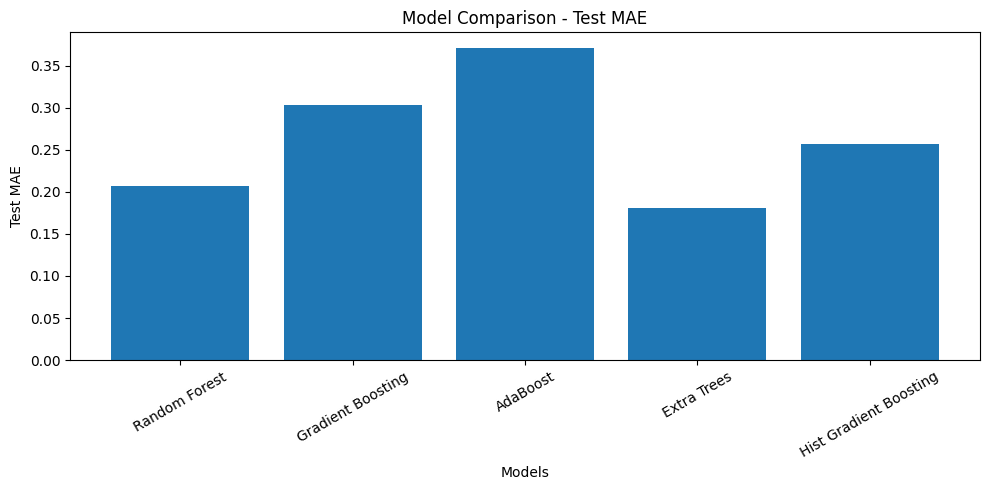

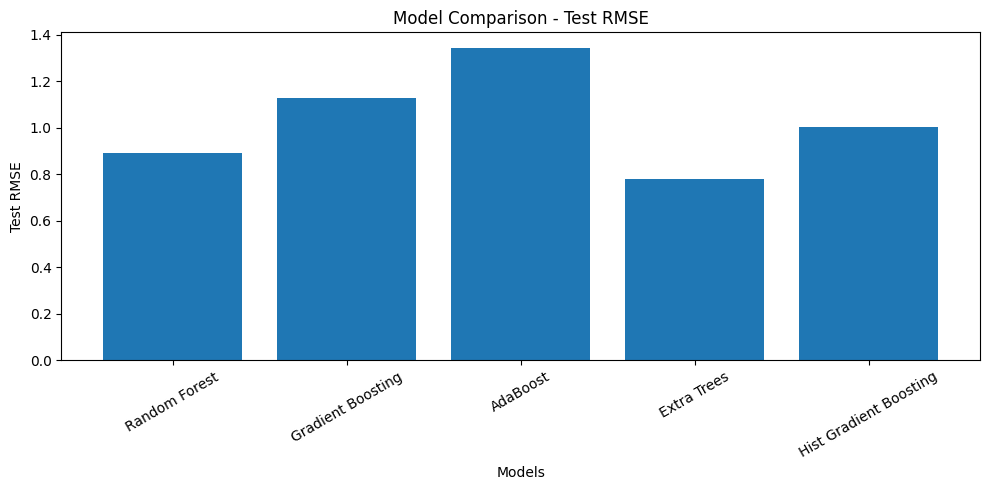

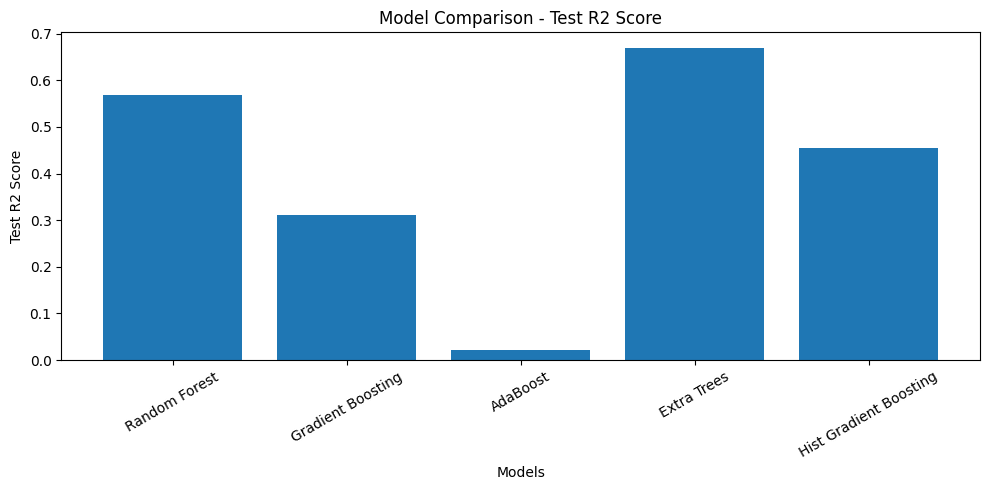

In [ ]:
import matplotlib.pyplot as plt

metrics = ["Test MAE", "Test RMSE", "Test R2 Score"]

for metric in metrics:

    plt.figure(figsize=(10, 5))

    plt.bar(
        best_comparison["Model"],
        best_comparison[metric]
    )

    plt.title("Model Comparison - " + metric)

    plt.xlabel("Models")

    plt.ylabel(metric)

    plt.xticks(rotation=30)

    plt.tight_layout()

    plt.show()

In [ ]:
all_results_df.to_csv(
    "All_135_Tuning_Results.csv",
    index=False
)

best_comparison.to_csv(
    "Best_Model_Comparison.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [ ]:
print("===== FINAL PROJECT RESULT =====")

print("Total Models:", len(best_models))

print("Total Combinations Tested:", len(all_results_df))

print("\nBest Performing Model:", final_best_model_name)

print("Best Parameters:", overall_best["Best Parameters"])

print("Best CV MAE:", overall_best["Best CV MAE"])

print("Test MAE:", overall_best["Test MAE"])

print("Test RMSE:", overall_best["Test RMSE"])

print("Test R2 Score:", overall_best["Test R2 Score"])

print("\nFINAL RESULT: Hyperparameter tuning completed successfully!")

===== FINAL PROJECT RESULT =====
Total Models: 5
Total Combinations Tested: 135

Best Performing Model: Extra Trees
Best Parameters: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 150}
Best CV MAE: 0.21750085963616744
Test MAE: 0.18091187852335577
Test RMSE: 0.78049607456039
Test R2 Score: 0.6694249355827304

FINAL RESULT: Hyperparameter tuning completed successfully!


In [ ]:
import time

prediction_times = []

for name, model in best_models.items():

    start_time = time.perf_counter()

    predictions = model.predict(X_test_selected)

    end_time = time.perf_counter()

    total_time = end_time - start_time

    prediction_times.append({
        "Model": name,
        "Prediction Time (seconds)": total_time,
        "Prediction Time (milliseconds)": total_time * 1000
    })

prediction_time_df = pd.DataFrame(prediction_times)

print("===== PREDICTION TIME COMPARISON =====")

display(prediction_time_df.round(6))

===== PREDICTION TIME COMPARISON =====


,Model,Prediction Time (seconds),Prediction Time (milliseconds)
0,Random Forest,0.200418,200.418071
1,Gradient Boosting,0.030707,30.706849
2,AdaBoost,0.008220,8.220236
3,Extra Trees,0.196850,196.849657
4,Hist Gradient Boosting,0.104417,104.417047


In [ ]:
prediction_time_df["Average Time Per Prediction (ms)"] = (
    prediction_time_df["Prediction Time (milliseconds)"]
    / len(X_test_selected)
)

display(prediction_time_df.round(6))

,Model,Prediction Time (seconds),Prediction Time (milliseconds),Average Time Per Prediction (ms)
0,Random Forest,0.200418,200.418071,0.030129
1,Gradient Boosting,0.030707,30.706849,0.004616
2,AdaBoost,0.008220,8.220236,0.001236
3,Extra Trees,0.196850,196.849657,0.029593
4,Hist Gradient Boosting,0.104417,104.417047,0.015697


In [ ]:
!pip install gradio

In [ ]:
!python app.py

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://c8a4b61b3b0a997188.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
